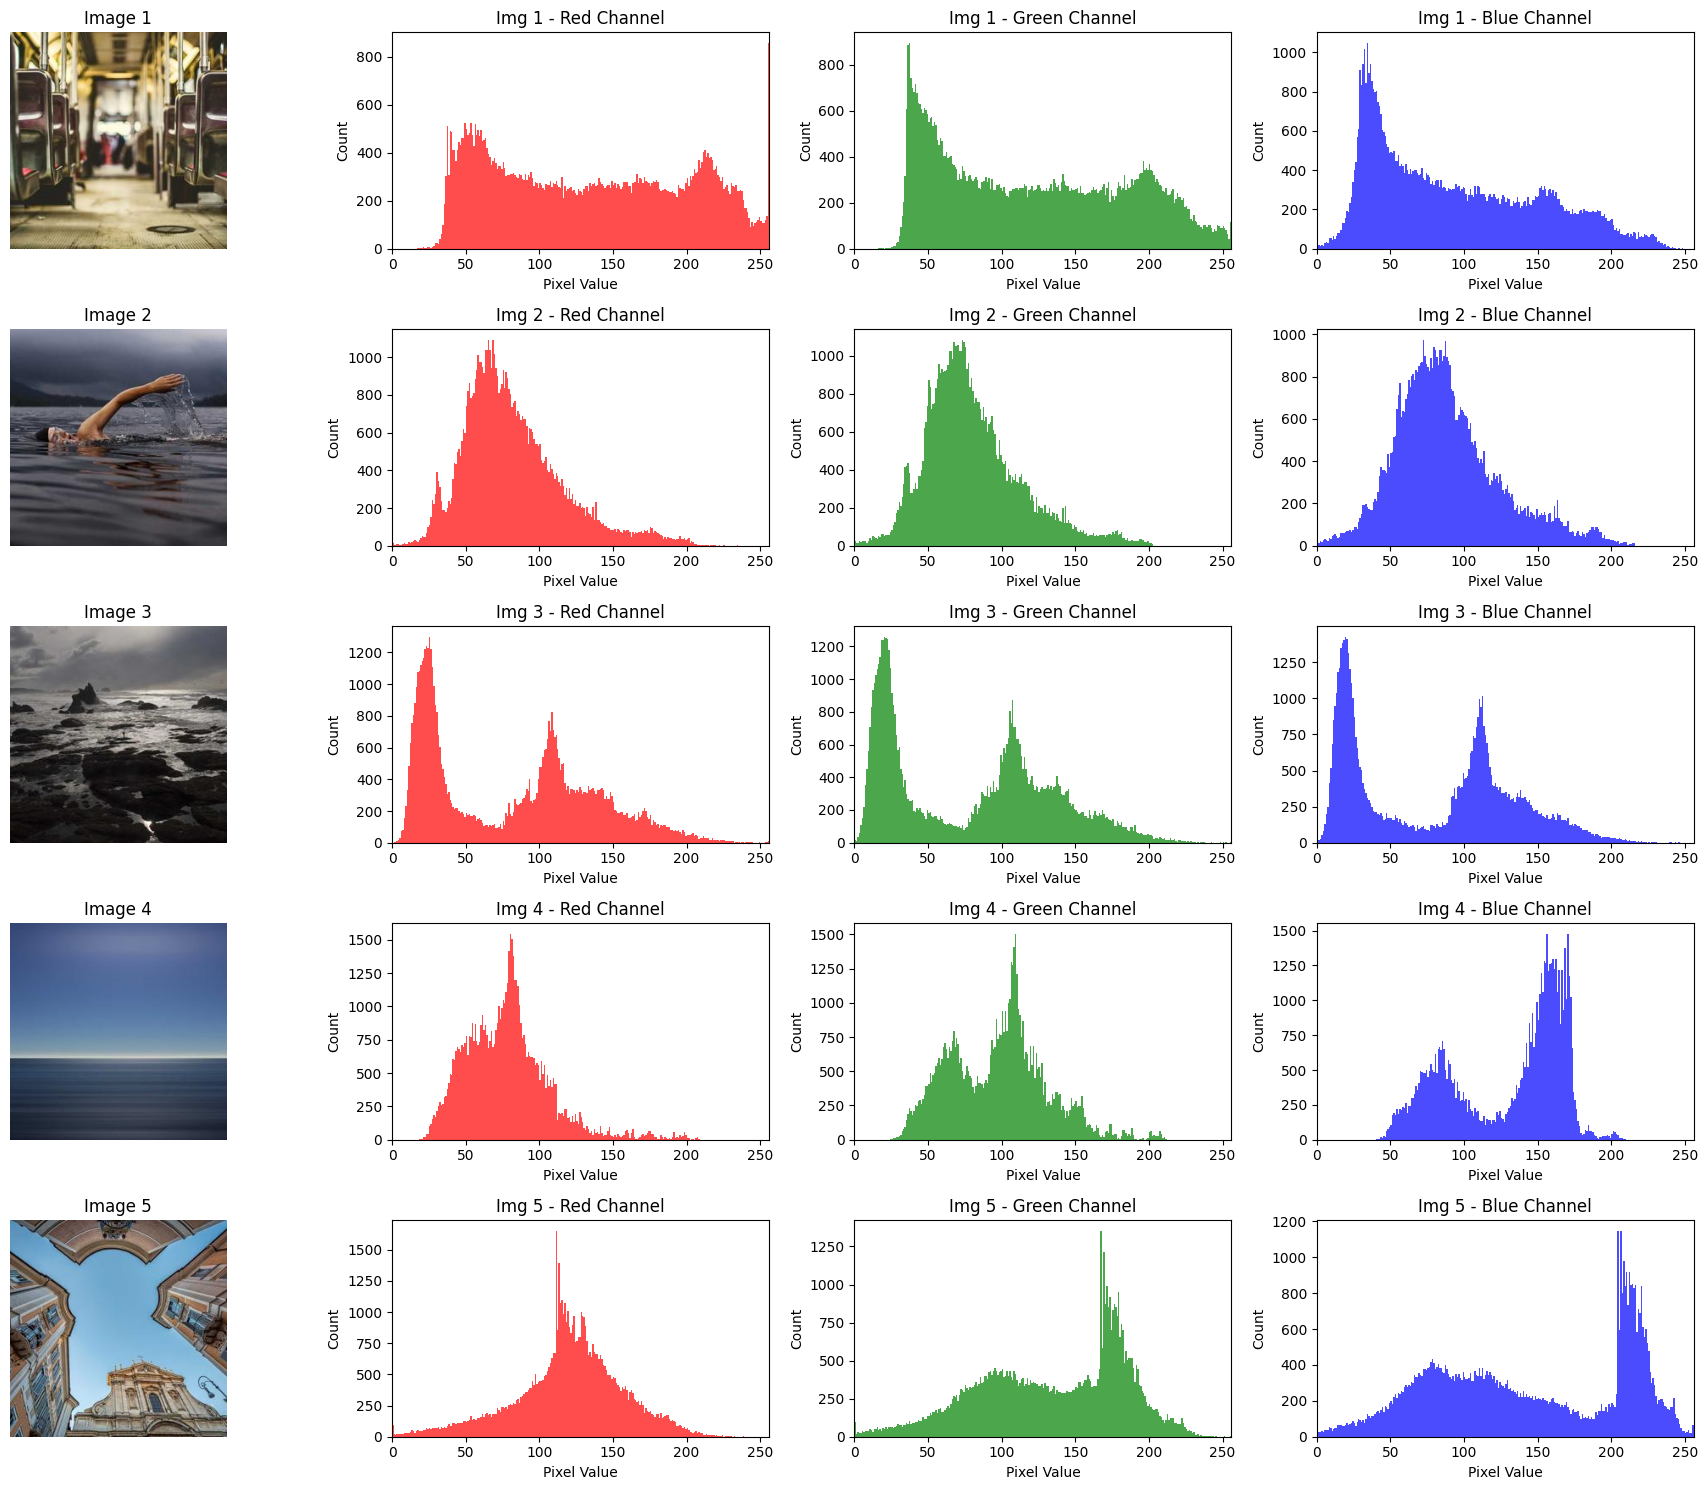

--- Image 1 ---
  Original Mean (R, G, B): [133.73 120.71  92.61]
  Original Std  (R, G, B): [65.33 63.52 56.38]
  Verified Mean (Expected ~0): [0.e+00 1.e-06 1.e-06]
  Verified Std  (Expected ~1): [1.000033 0.999985 1.000004]

--- Image 2 ---
  Original Mean (R, G, B): [81.79 80.02 88.25]
  Original Std  (R, G, B): [34.14 32.8  35.87]
  Verified Mean (Expected ~0): [-4.9e-05 -1.0e-06 -6.0e-06]
  Verified Std  (Expected ~1): [0.99999 1.00004 1.00001]

--- Image 3 ---
  Original Mean (R, G, B): [81.24 78.79 78.01]
  Original Std  (R, G, B): [55.31 55.1  54.29]
  Verified Mean (Expected ~0): [ 1.e-06 -1.e-06 -7.e-06]
  Verified Std  (Expected ~1): [0.999993 0.999959 0.999996]

--- Image 4 ---
  Original Mean (R, G, B): [ 77.31  97.17 129.53]
  Original Std  (R, G, B): [28.39 32.79 38.42]
  Verified Mean (Expected ~0): [6.e-06 4.e-06 3.e-06]
  Verified Std  (Expected ~1): [0.999999 0.999989 0.999983]

--- Image 5 ---
  Original Mean (R, G, B): [119.55 134.09 142.56]
  Original Std  (R, G,

In [63]:
import io
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 5 darab 256x256-os képet kérünk le a Picsum nyilvános API-jából
images = []

for i in range(5):
    # A random paraméter biztosítja, hogy 5 különböző képet kapjunk
    url = f"https://picsum.photos/256/256?random={i+1}"

    # A böngésző azonosító (User-Agent) megadása elkerüli a HTTP 403-as blokkolást
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})

    with urllib.request.urlopen(req) as response:
        # Bájtok beolvasása és átalakítása RGB PIL képpé
        img_pil = Image.open(io.BytesIO(response.read())).convert("RGB")

        # Átalakítás NumPy tömbbé (256, 256, 3) méretben
        img_array = np.array(img_pil)
        images.append(img_array)

import matplotlib.pyplot as plt

# 5 sor és 4 oszlop létrehozása (1 oszlop a képnek + 3 oszlop az R, G, B hisztogramoknak)
fig, axes = plt.subplots(5, 4, figsize=(18, 15))

colors = ('red', 'green', 'blue')
channel_names = ('Red', 'Green', 'Blue')

for i, img in enumerate(images):
    # --- 1. A kép megjelenítése (0. oszlop) ---
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Image {i+1}")
    axes[i, 0].axis('off')

    # --- 2. Különálló R, G, B hisztogramok (1., 2. és 3. oszlop) ---
    for j in range(3):
        channel_data = img[:, :, j].ravel()  # A j-edik csatorna 1D-s tömbbé lapítása

        axes[i, j+1].hist(
            channel_data,
            bins=256,
            range=(0, 256),
            color=colors[j],
            alpha=0.7
        )
        axes[i, j+1].set_title(f"Img {i+1} - {channel_names[j]} Channel")
        axes[i, j+1].set_xlim([0, 256])
        axes[i, j+1].set_xlabel("Pixel Value")
        axes[i, j+1].set_ylabel("Count")

plt.tight_layout()
plt.show()

for i, img in enumerate(images):
    # Átalakítjuk lebegőpontos (float32) típussá a pontos matematikai műveletekhez
    img_float = img.astype(np.float32)

    # 1. Eredeti átlag és szórás kiszámítása csatornánként (R, G, B)
    # axis=(0, 1) -> a magasság és szélesség mentén átlagol, megtartva a 3 csatornát
    # keepdims=True -> (1, 1, 3) alakot ad, így könnyű vele műveletet végezni
    mean = np.mean(img_float, axis=(0, 1), keepdims=True)
    std = np.std(img_float, axis=(0, 1), keepdims=True)

    # 2. Standardizálás (0 várható érték, 1 szórás)
    # Az epszilon (1e-8) elkerüli a 0-val való osztást, ha a szórás 0 lenne
    standardized_img = (img_float - mean) / (std + 1e-8)

    # 3. Ellenőrzés: Az új adathalmaz átlaga és szórása csatornánként
    new_mean = np.mean(standardized_img, axis=(0, 1))
    new_std = np.std(standardized_img, axis=(0, 1))

    # Eredmények kiíratása
    print(f"--- Image {i+1} ---")
    print(f"  Original Mean (R, G, B): {mean.ravel().round(2)}")
    print(f"  Original Std  (R, G, B): {std.ravel().round(2)}")
    print(f"  Verified Mean (Expected ~0): {new_mean.round(6)}")
    print(f"  Verified Std  (Expected ~1): {new_std.round(6)}\n")




#


Downloading: https://upload.wikimedia.org/wikipedia/commons/5/57/Sclerurus_albigularis_-_Grey-throated_Leaftosser_XC249833.mp3
  status=200, content-type=audio/mpeg, bytes=377616
Downloading: https://upload.wikimedia.org/wikipedia/commons/0/03/%27A_difficult_moment_for_America%27%2C_George_W._Bush%2C_September_11%2C_2001.oga
  status=200, content-type=application/ogg, bytes=3293493

Audio 1 — eredeti (dB)        mean=-62.4114  std=12.3738  min=-80.00  max=+0.00
Audio 1 — standardizált       mean=+0.0000  std=1.0000  min=-1.42  max=+5.04
Audio 2 — eredeti (dB)        mean=-70.7806  std=12.0754  min=-80.00  max=+0.00
Audio 2 — standardizált       mean=-0.0000  std=1.0000  min=-0.76  max=+5.86



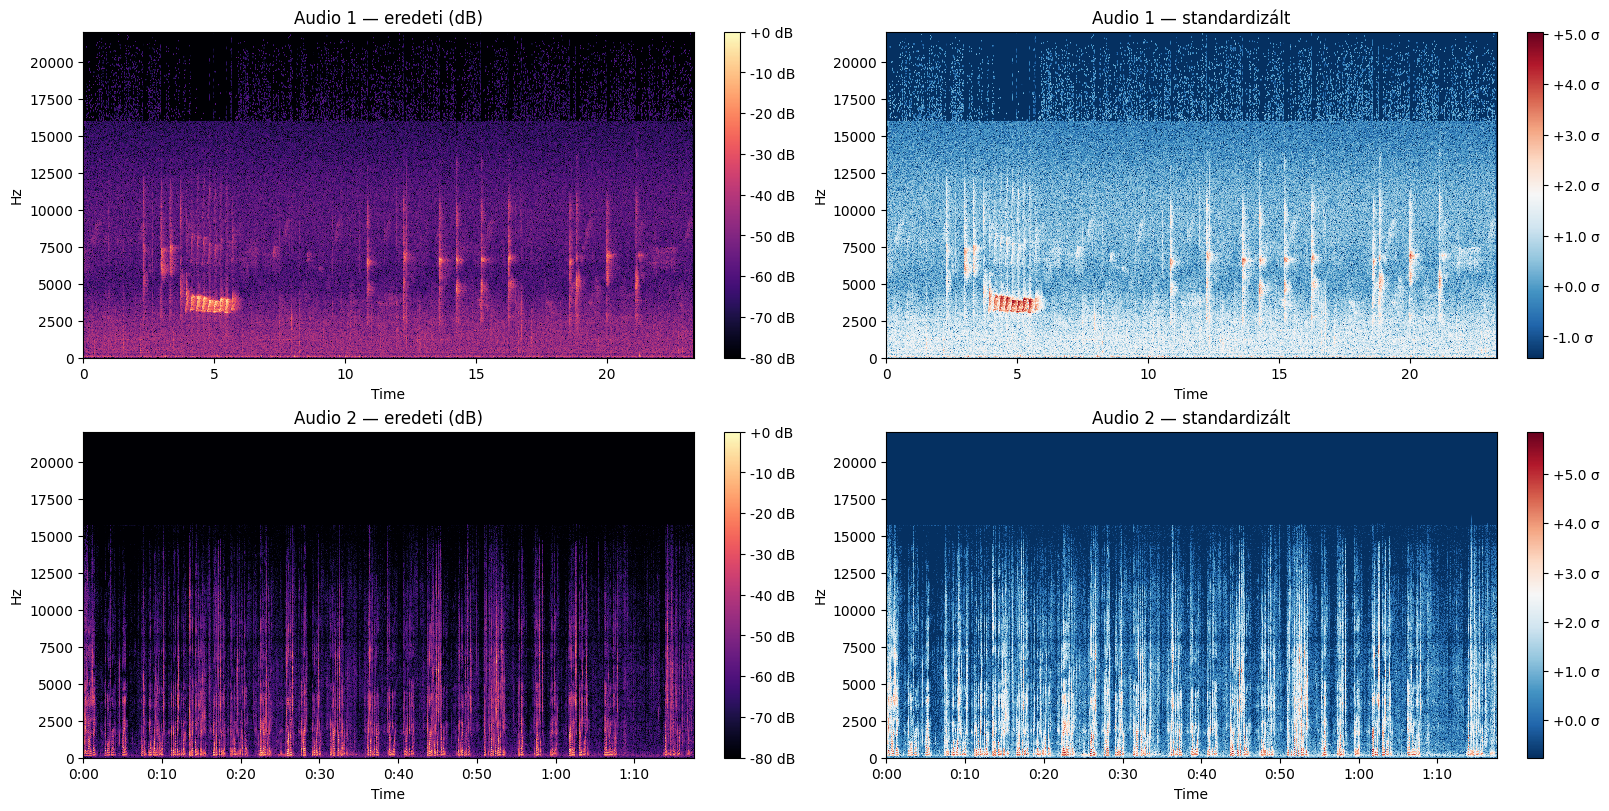

In [64]:
import io
import re
import requests
import urllib.request
import librosa
import numpy as np
import matplotlib.pyplot as plt
import librosa.display

HEADERS = {
    "User-Agent": "AudioSpectrogramBot/1.0 (https://github.com/yulangrichard/DL_kishazi1) Python/requests"

}


def clean_url(url):
    """Strip tracking query params that Wikimedia's CDN dislikes."""
    return url.split("?")[0]


def resolve_commons_url(page_url):
    """Turn a Commons File: page into the direct upload.wikimedia.org URL."""
    if "commons.wikimedia.org/wiki/" not in page_url:
        return page_url
    title = page_url.split("/wiki/")[-1]
    api = "https://commons.wikimedia.org/w/api.php"
    r = requests.get(
        api,
        params={
            "action": "query",
            "titles": title,
            "prop": "imageinfo",
            "iiprop": "url",
            "format": "json",
        },
        headers=HEADERS,
    )
    r.raise_for_status()
    info = next(iter(r.json()["query"]["pages"].values()))["imageinfo"][0]
    return info["url"]


def load_audio_from_url(url):
    url = clean_url(resolve_commons_url(url))
    print(f"Downloading: {url}")
    r = requests.get(url, headers=HEADERS)
    r.raise_for_status()
    print(f"  status={r.status_code}, content-type={r.headers.get('Content-Type')}, "
          f"bytes={len(r.content)}")
    audio, sr = librosa.load(io.BytesIO(r.content), sr=None, mono=True)
    return audio, sr


# ---------- ÚJ: spektrogram + standardizálás ----------

def compute_spectrogram_db(audio, sr):
    """Visszaadja a dB-spektrogramot ÉS a hop_length-et (a rajzoláshoz kell)."""
    hop_length = 512
    D = librosa.stft(audio, hop_length=hop_length)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    return S_db, hop_length


def zscore_global(S):
    """Globális standardizálás az egész mátrixon (alternatíva)."""
    return (S - S.mean()) / (S.std() + 1e-8)


def verify_stats(name, S):
    """Ellenőrzés: átlag ~0, szórás ~1."""
    print(f"{name:28s}  mean={S.mean():+.4f}  std={S.std():.4f}  "
          f"min={S.min():+.2f}  max={S.max():+.2f}")


# ---------- Rajzolás ----------

def plot_spectrogram(ax, S, sr, hop_length, title, cmap="magma"):
    img = librosa.display.specshow(
        S, sr=sr, hop_length=hop_length,
        x_axis="time", y_axis="hz",
        ax=ax, cmap=cmap,
    )
    ax.set_title(title)
    return img


def main():
    url1 = "https://upload.wikimedia.org/wikipedia/commons/5/57/Sclerurus_albigularis_-_Grey-throated_Leaftosser_XC249833.mp3?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original"
    url2 = "https://upload.wikimedia.org/wikipedia/commons/0/03/%27A_difficult_moment_for_America%27%2C_George_W._Bush%2C_September_11%2C_2001.oga?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original"

    audio1, sr1 = load_audio_from_url(url1)
    audio2, sr2 = load_audio_from_url(url2)

    # 1) dB-spektrogramok
    S1_db, hop1 = compute_spectrogram_db(audio1, sr1)
    S2_db, hop2 = compute_spectrogram_db(audio2, sr2)

    # 2) Standardizálás frekvenciánként
    S1_z = zscore_global(S1_db)
    S2_z = zscore_global(S2_db)

    # 3) Ellenőrzés
    print()
    verify_stats("Audio 1 — eredeti (dB)", S1_db)
    verify_stats("Audio 1 — standardizált", S1_z)
    verify_stats("Audio 2 — eredeti (dB)", S2_db)
    verify_stats("Audio 2 — standardizált", S2_z)
    print()

    # 4) Ábrázolás: bal = eredeti dB, jobb = standardizált
    fig, axes = plt.subplots(2, 2, figsize=(16, 8), constrained_layout=True)

    img00 = plot_spectrogram(axes[0, 0], S1_db, sr1, hop1,
                             "Audio 1 — eredeti (dB)")
    img01 = plot_spectrogram(axes[0, 1], S1_z, sr1, hop1,
                             "Audio 1 — standardizált", cmap="RdBu_r")
    img10 = plot_spectrogram(axes[1, 0], S2_db, sr2, hop2,
                             "Audio 2 — eredeti (dB)")
    img11 = plot_spectrogram(axes[1, 1], S2_z, sr2, hop2,
                             "Audio 2 — standardizált", cmap="RdBu_r")

    # Színskála: dB-nél dB, z-score-nál szórás-egységek
    fig.colorbar(img00, ax=axes[0, 0], format="%+2.0f dB")
    fig.colorbar(img10, ax=axes[1, 0], format="%+2.0f dB")
    fig.colorbar(img01, ax=axes[0, 1], format="%+.1f σ")
    fig.colorbar(img11, ax=axes[1, 1], format="%+.1f σ")

    plt.show()


if __name__ == "__main__":
    main()

Sikeres letöltés: https://smartlab.tmit.bme.hu/oktatas-deep-learning (status=200)

===== AZ OLDAL LÁTHATÓ SZÖVEGES TARTALMA =====

﻿ Languages Magyar English Menü be/kikapcsolás RÓLUNK Laborunkról Munkatársaink Média megjelenések MEGOLDÁSAINK Profivox magyar nyelvű felolvasó (korpuszos) Profivox magyar nyelvű felolvasó (DNN) Profivox magyar nyelvű felolvasó (HMM) Profivox magyar nyelvű felolvasó (diádos,triádos) StrokeAid Alkalmazások Jaws for Windows integráció Időjárás mindenkinek (magyar, Windows 8) AALFred (5 nyelven, Windows 8.1) Robobraille Beszélő ATM-ek Gyógyszervonal (OGYI) Árlista felolvasó (T-mobile) Keleti pályaudvar bemondórendszere Mindenség elmélete c. film gépi beszéd szinkron K+F Kutatási projektek (folyamatban) Kutatási projektek (befejezett) Publikációk (összes) Publikációk (kiemelt) Letölthető könyvek OKTATÁS KAPCSOLAT BLOG DEEP LEARNING A GYAKORLATBAN PYTHON ÉS LUA ALAPON Kezdőlap Oktatás Deep Learning Ha a tárgyról lecsúsztál, de szeretnél a deep learningbe beleke

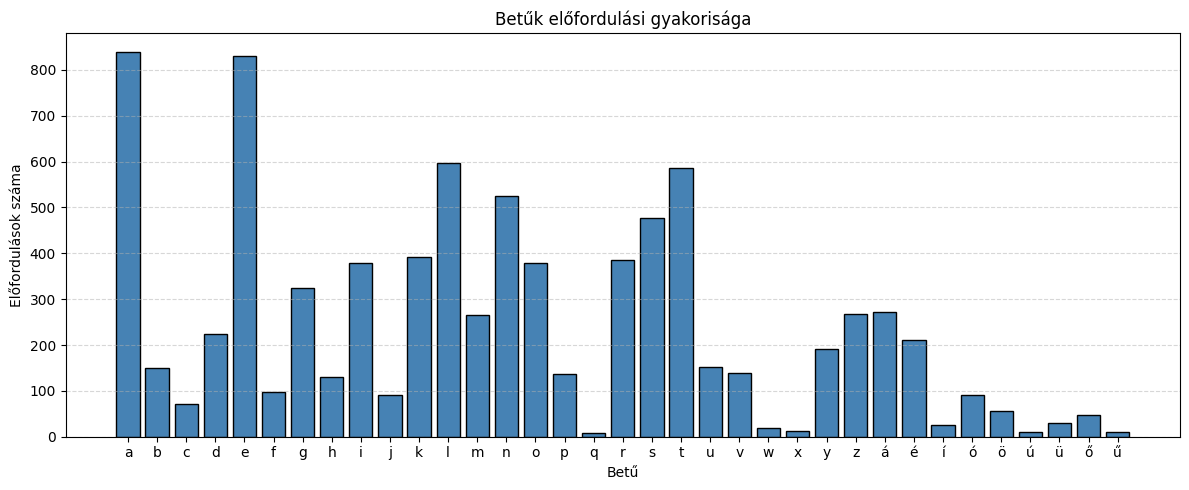

In [65]:
import requests
from bs4 import BeautifulSoup
from collections import Counter
import matplotlib.pyplot as plt


# ... a többi kód változatlan

URL = "http://smartlab.tmit.bme.hu/oktatas-deep-learning"

# Ez a kulcs! Egy modern böngésző User-Agent-je.
HEADERS = {
    "User-Agent": "AudioSpectrogramBot/1.0 (https://github.com/yulangrichard/DL_kishazi1) Python/requests"

}

def fetch_html(url):
    """Letölti a HTML-t, és követi az esetleges átirányításokat."""
    # A requests automatikusan kezeli a 301-es átirányítást, ha az URL http://
    # A timeout és a headers megadása elengedhetetlen.

    r = requests.get(url, headers=HEADERS, timeout=15, verify="/content/smartlab-tmit-bme-hu-chain.pem")
    r.raise_for_status()  # Hibát dob, ha a státuszkód nem 200
    print(f"Sikeres letöltés: {r.url} (status={r.status_code})")
    return r.text

def visible_text(html):
    """Visszaadja a HTML-ből a látható szöveget."""
    soup = BeautifulSoup(html, "html.parser")
    # Nem látható elemek eltávolítása
    for tag in soup(["script", "style", "noscript", "head", "meta", "link"]):
        tag.decompose()
    # A maradék szöveg kinyerése és whitespace normalizálása
    text = soup.get_text(separator=" ")
    return " ".join(text.split())

def main():
    try:
        html = fetch_html(URL)
        text = visible_text(html)
    except Exception as e:
        # Ha valamiért mégis hiba lenne, itt kezelhetjük, de a fenti fejléccel menni fog.
        print(f"Váratlan hiba: {e}")
        return

    print("\n===== AZ OLDAL LÁTHATÓ SZÖVEGES TARTALMA =====\n")
    print(text[:3000] + ("…" if len(text) > 3000 else ""))
    print(f"\n[Teljes hossz: {len(text)} karakter]")

    # Betűgyakoriság
    letters = [c.lower() for c in text if c.isalpha()]
    counter = Counter(letters)
    letters_sorted = sorted(counter.keys())
    counts = [counter[c] for c in letters_sorted]

    print("\n===== BETŰGYAKORISÁG =====\n")
    for c, n in zip(letters_sorted, counts):
        print(f"  '{c}': {n}")

    # Hisztogram
    plt.figure(figsize=(12, 5))
    plt.bar(letters_sorted, counts, color="steelblue", edgecolor="black")
    plt.title("Betűk előfordulási gyakorisága")
    plt.xlabel("Betű")
    plt.ylabel("Előfordulások száma")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()